In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import scipy

print("DEN702 WiFi notebook ready")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

DEN702 WiFi notebook ready
Pandas: 3.0.6
Scikit-learn: 1.9.1


In [2]:
train = pd.read_csv("../data/raw/trainingData.csv")
test = pd.read_csv("../data/raw/validationData.csv")

print("Training shape:", train.shape)
print("Validation shape:", test.shape)

Training shape: (19937, 529)
Validation shape: (1111, 529)


## Step 1 — Import Required Libraries

This step imports the Python libraries needed for dataset exploration and verifies that the DEN702 Wi-Fi research environment is working correctly.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import scipy

print("DEN702 WiFi notebook ready")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

DEN702 WiFi notebook ready
Pandas: 3.0.6
Scikit-learn: 1.9.1


## Step 2 — Load the UJIIndoorLoc Dataset

This step loads the official UJIIndoorLoc training and validation datasets from the `data/raw` folder and checks their dimensions.

In [4]:
train = pd.read_csv("../data/raw/trainingData.csv")
test = pd.read_csv("../data/raw/validationData.csv")

print("Training shape:", train.shape)
print("Validation shape:", test.shape)

Training shape: (19937, 529)
Validation shape: (1111, 529)


## Step 3 — Identify Wi-Fi Access Point Features

This step identifies all columns representing Wi-Fi Access Points (WAPs). These RSSI features will later be used for localization and robustness experiments.

In [5]:
wifi_cols = [col for col in train.columns if col.startswith("WAP")]

print("Number of Wi-Fi AP features:", len(wifi_cols))
print("First 10 AP columns:")
print(wifi_cols[:10])

Number of Wi-Fi AP features: 520
First 10 AP columns:
['WAP001', 'WAP002', 'WAP003', 'WAP004', 'WAP005', 'WAP006', 'WAP007', 'WAP008', 'WAP009', 'WAP010']


## Step 4 — Inspect Location Labels and Coordinates

This step examines the main target variables used for indoor localization, including building ID, floor, longitude, and latitude.

In [6]:
location_cols = [
    "LONGITUDE",
    "LATITUDE",
    "FLOOR",
    "BUILDINGID"
]

display(train[location_cols].head())

print("Buildings:", sorted(train["BUILDINGID"].unique()))
print("Floors:", sorted(train["FLOOR"].unique()))

,LONGITUDE,LATITUDE,FLOOR,BUILDINGID
0,-7541.2643,4.864921e+06,2,1
1,-7536.6212,4.864934e+06,2,1
2,-7519.1524,4.864950e+06,2,1
3,-7524.5704,4.864934e+06,2,1
4,-7632.1436,4.864982e+06,0,0


Buildings: [np.int64(0), np.int64(1), np.int64(2)]
Floors: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## Step 5 — Inspect RSSI Values and Undetected Access Points

This step examines the minimum and maximum Wi-Fi RSSI values and counts how many entries use the value `100`, which represents an undetected Access Point in the UJIIndoorLoc dataset.

No values are modified at this stage.

In [7]:
print("RSSI minimum:", train[wifi_cols].min().min())
print("RSSI maximum:", train[wifi_cols].max().max())

missing_ap_count = (train[wifi_cols] == 100).sum().sum()

print("Values equal to 100:", missing_ap_count)

RSSI minimum: -104
RSSI maximum: 100
Values equal to 100: 10008477


## Step 6 — Calculate the Percentage of Undetected Access Points

This step calculates how sparse the Wi-Fi fingerprint matrix is by measuring the percentage of Wi-Fi readings where an Access Point was not detected.

In [8]:
total_wifi_values = train[wifi_cols].size

missing_percentage = (
    missing_ap_count
    / total_wifi_values
    * 100
)

print(f"Undetected AP percentage: {missing_percentage:.2f}%")

Undetected AP percentage: 96.54%


## Step 7 — Inspect Building and Floor Distribution

This step checks how training samples are distributed across buildings and floors. A combined building-floor label is also created for later classification experiments.

In [9]:
print("Building distribution:")
print(train["BUILDINGID"].value_counts().sort_index())

print("\nFloor distribution:")
print(train["FLOOR"].value_counts().sort_index())

train["BUILDING_FLOOR"] = (
    train["BUILDINGID"].astype(str)
    + "_"
    + train["FLOOR"].astype(str)
)

test["BUILDING_FLOOR"] = (
    test["BUILDINGID"].astype(str)
    + "_"
    + test["FLOOR"].astype(str)
)

print("\nCombined Building-Floor distribution:")
print(train["BUILDING_FLOOR"].value_counts().sort_index())

Building distribution:
BUILDINGID
0    5249
1    5196
2    9492
Name: count, dtype: int64

Floor distribution:
FLOOR
0    4369
1    5002
2    4416
3    5048
4    1102
Name: count, dtype: int64

Combined Building-Floor distribution:
BUILDING_FLOOR
0_0    1059
0_1    1356
0_2    1443
0_3    1391
1_0    1368
1_1    1484
1_2    1396
1_3     948
2_0    1942
2_1    2162
2_2    1577
2_3    2709
2_4    1102
Name: count, dtype: int64


/var/folders/bs/nxwjt6v57wqd854rv2409k3m0000gn/T/ipykernel_27571/1142372584.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["BUILDING_FLOOR"] = (
/var/folders/bs/nxwjt6v57wqd854rv2409k3m0000gn/T/ipykernel_27571/1142372584.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test["BUILDING_FLOOR"] = (


## Step 8 — Inspect Coordinate Statistics

This step summarizes the longitude and latitude values used for coordinate-based indoor localization.

In [10]:
display(
    train[["LONGITUDE", "LATITUDE"]].describe()
)

,LONGITUDE,LATITUDE
count,19937.000000,1.993700e+04
mean,-7464.275947,4.864871e+06
std,123.402010,6.693318e+01
min,-7691.338400,4.864746e+06
25%,-7594.737000,4.864821e+06
50%,-7423.060900,4.864852e+06
75%,-7359.193000,4.864930e+06
max,-7300.818990,4.865017e+06


## Step 9 — Visualize the Spatial Distribution of Training Samples

This exploratory figure displays the spatial distribution of training reference points using longitude and latitude.

This figure is for dataset understanding only and is not yet considered a final publication figure.

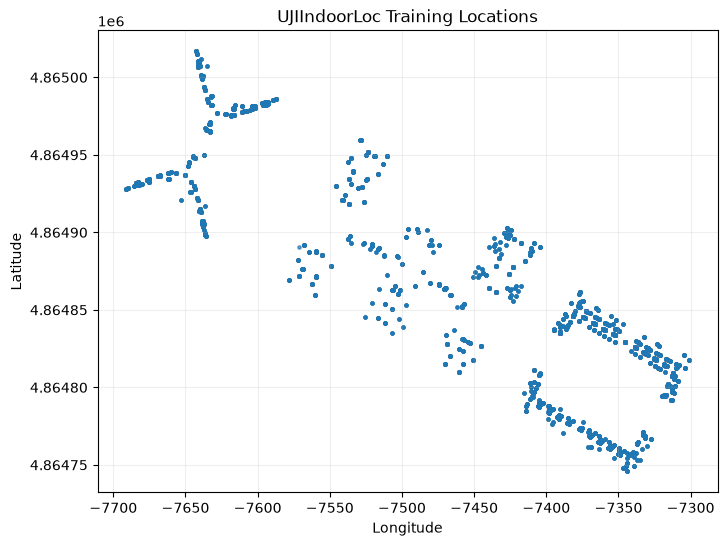

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    train["LONGITUDE"],
    train["LATITUDE"],
    s=5,
    alpha=0.3
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("UJIIndoorLoc Training Locations")
plt.grid(alpha=0.2)

plt.show()

## Step 10 — Generate Dataset Summary

This step summarizes the main dataset characteristics that will later be used in the Experimental Setup and Dataset sections of the research paper.

In [12]:
print("=== UJIIndoorLoc Dataset Summary ===")
print("Training samples:", train.shape[0])
print("Validation samples:", test.shape[0])
print("Total columns:", train.shape[1])
print("Wi-Fi AP features:", len(wifi_cols))
print("Buildings:", train["BUILDINGID"].nunique())
print("Floors:", train["FLOOR"].nunique())
print("RSSI minimum:", train[wifi_cols].min().min())
print("RSSI maximum:", train[wifi_cols].max().max())
print("Undetected AP values:", missing_ap_count)
print(f"Undetected AP percentage: {missing_percentage:.2f}%")

=== UJIIndoorLoc Dataset Summary ===
Training samples: 19937
Validation samples: 1111
Total columns: 530
Wi-Fi AP features: 520
Buildings: 3
Floors: 5
RSSI minimum: -104
RSSI maximum: 100
Undetected AP values: 10008477
Undetected AP percentage: 96.54%


DEN702 WiFi Dataset Exploration

Environment:
Pandas: 3.0.6
NumPy: 2.4.6
Scikit-learn: 1.9.1
SciPy: 1.17.1

Project root:
/Users/am/Documents/ADU/wifi-localization-research

Training file:
/Users/am/Documents/ADU/wifi-localization-research/data/raw/trainingData.csv

Validation file:
/Users/am/Documents/ADU/wifi-localization-research/data/raw/validationData.csv

STEP 3 — DATASET LOADED
Training shape: (19937, 529)
Validation shape: (1111, 529)

STEP 4 — WI-FI FEATURES
Number of Wi-Fi AP features: 520

First 10 Wi-Fi columns:
['WAP001', 'WAP002', 'WAP003', 'WAP004', 'WAP005', 'WAP006', 'WAP007', 'WAP008', 'WAP009', 'WAP010']

STEP 5 — LOCATION INFORMATION

First five location records:


,LONGITUDE,LATITUDE,FLOOR,BUILDINGID
0,-7541.2643,4.864921e+06,2,1
1,-7536.6212,4.864934e+06,2,1
2,-7519.1524,4.864950e+06,2,1
3,-7524.5704,4.864934e+06,2,1
4,-7632.1436,4.864982e+06,0,0


Buildings: [np.int64(0), np.int64(1), np.int64(2)]
Floors: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

STEP 6 — RSSI AND UNDETECTED ACCESS POINTS
RSSI minimum: -104
RSSI maximum: 100
Values equal to 100: 10008477

STEP 7 — WI-FI FINGERPRINT SPARSITY
Total Wi-Fi values: 10367240
Undetected AP percentage: 96.54%

STEP 8 — BUILDING AND FLOOR DISTRIBUTION

Building distribution:
BUILDINGID
0    5249
1    5196
2    9492
Name: count, dtype: int64

Floor distribution:
FLOOR
0    4369
1    5002
2    4416
3    5048
4    1102
Name: count, dtype: int64

Combined Building-Floor distribution:
BUILDING_FLOOR
0_0    1059
0_1    1356
0_2    1443
0_3    1391
1_0    1368
1_1    1484
1_2    1396
1_3     948
2_0    1942
2_1    2162
2_2    1577
2_3    2709
2_4    1102
Name: count, dtype: int64

Number of Building-Floor classes: 13

STEP 9 — COORDINATE STATISTICS


/var/folders/bs/nxwjt6v57wqd854rv2409k3m0000gn/T/ipykernel_27571/1799223307.py:253: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["BUILDING_FLOOR"] = (
/var/folders/bs/nxwjt6v57wqd854rv2409k3m0000gn/T/ipykernel_27571/1799223307.py:259: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  test["BUILDING_FLOOR"] = (


,LONGITUDE,LATITUDE
count,19937.000000,1.993700e+04
mean,-7464.275947,4.864871e+06
std,123.402010,6.693318e+01
min,-7691.338400,4.864746e+06
25%,-7594.737000,4.864821e+06
50%,-7423.060900,4.864852e+06
75%,-7359.193000,4.864930e+06
max,-7300.818990,4.865017e+06


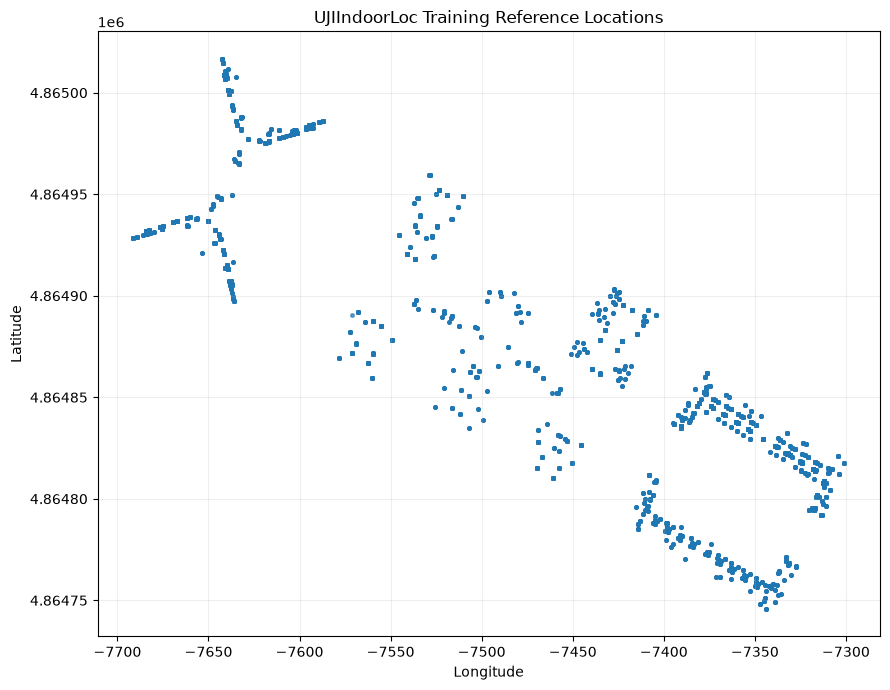


Exploratory figure saved to:
/Users/am/Documents/ADU/wifi-localization-research/results/figures/01_training_locations_exploratory.png

STEP 11 — MISSING VALUE CHECK
Training NaN values: 0
Validation NaN values: 0

DEN702 — UJIIndoorLoc DATASET SUMMARY


,Characteristic,Value
0,Training Samples,1.993700e+04
1,Validation Samples,1.111000e+03
2,Original Columns,5.290000e+02
3,WiFi AP Features,5.200000e+02
4,Buildings,3.000000e+00
5,Floors,5.000000e+00
6,Building-Floor Classes,1.300000e+01
7,RSSI Minimum,-1.040000e+02
8,RSSI Maximum,1.000000e+02
9,Undetected AP Values,1.000848e+07



Dataset summary saved to:
/Users/am/Documents/ADU/wifi-localization-research/results/csv/01_dataset_summary.csv

NOTEBOOK 01 COMPLETED SUCCESSFULLY
Training samples: 19937
Validation samples: 1111
Wi-Fi AP features: 520
Buildings: 3
Floors: 5
Building-Floor classes: 13
RSSI range: -104 to 100
Undetected AP values: 10008477
Undetected AP percentage: 96.54%

Notebook 01 is complete.
Next notebook: 02_preprocessing.ipynb


In [13]:
# ============================================================
# DEN702 Research Paper
# Notebook 01 — UJIIndoorLoc Dataset Exploration
# Project: Robust Wi-Fi Fingerprint-Based Indoor Localization
# ============================================================


# ------------------------------------------------------------
# Step 1 — Import Required Libraries
#
# This step imports the Python libraries required for dataset
# exploration and verifies the research environment.
# ------------------------------------------------------------

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import scipy


print("=" * 60)
print("DEN702 WiFi Dataset Exploration")
print("=" * 60)

print("\nEnvironment:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)


# ------------------------------------------------------------
# Step 2 — Define Project Paths
#
# This automatically detects whether the notebook is being run
# from the notebooks folder or from the project root.
# ------------------------------------------------------------

if Path("../data/raw/trainingData.csv").exists():
    PROJECT_ROOT = Path("..").resolve()

elif Path("data/raw/trainingData.csv").exists():
    PROJECT_ROOT = Path(".").resolve()

else:
    raise FileNotFoundError(
        "Could not find data/raw/trainingData.csv.\n"
        "Make sure trainingData.csv and validationData.csv "
        "are inside data/raw/."
    )


RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"

RESULTS_CSV_DIR = PROJECT_ROOT / "results" / "csv"
RESULTS_FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

RESULTS_CSV_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)


TRAIN_FILE = RAW_DATA_DIR / "trainingData.csv"
VALIDATION_FILE = RAW_DATA_DIR / "validationData.csv"


print("\nProject root:")
print(PROJECT_ROOT)

print("\nTraining file:")
print(TRAIN_FILE)

print("\nValidation file:")
print(VALIDATION_FILE)


# ------------------------------------------------------------
# Step 3 — Load the UJIIndoorLoc Dataset
#
# This step loads the official training and validation datasets
# without modifying the original CSV files.
# ------------------------------------------------------------

train = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(VALIDATION_FILE)


print("\n" + "=" * 60)
print("STEP 3 — DATASET LOADED")
print("=" * 60)

print("Training shape:", train.shape)
print("Validation shape:", test.shape)


# ------------------------------------------------------------
# Step 4 — Identify Wi-Fi Access Point Features
#
# Wi-Fi fingerprint features are stored in columns beginning
# with WAP.
# ------------------------------------------------------------

wifi_cols = [
    column
    for column in train.columns
    if column.startswith("WAP")
]


print("\n" + "=" * 60)
print("STEP 4 — WI-FI FEATURES")
print("=" * 60)

print("Number of Wi-Fi AP features:", len(wifi_cols))

print("\nFirst 10 Wi-Fi columns:")
print(wifi_cols[:10])


# ------------------------------------------------------------
# Step 5 — Inspect Location Labels and Coordinates
#
# These variables will later be used for:
#
# 1. Building-floor classification
# 2. Coordinate localization/regression
# ------------------------------------------------------------

location_cols = [
    "LONGITUDE",
    "LATITUDE",
    "FLOOR",
    "BUILDINGID"
]


print("\n" + "=" * 60)
print("STEP 5 — LOCATION INFORMATION")
print("=" * 60)

print("\nFirst five location records:")

display(
    train[location_cols].head()
)


buildings = sorted(
    train["BUILDINGID"].unique()
)

floors = sorted(
    train["FLOOR"].unique()
)


print("Buildings:", buildings)
print("Floors:", floors)


# ------------------------------------------------------------
# Step 6 — Inspect RSSI Values and Undetected Access Points
#
# In UJIIndoorLoc, the value 100 represents an access point
# that was NOT detected.
#
# No RSSI values are changed in this exploration notebook.
# ------------------------------------------------------------

rssi_min = train[wifi_cols].min().min()
rssi_max = train[wifi_cols].max().max()

missing_ap_count = (
    train[wifi_cols] == 100
).sum().sum()


print("\n" + "=" * 60)
print("STEP 6 — RSSI AND UNDETECTED ACCESS POINTS")
print("=" * 60)

print("RSSI minimum:", rssi_min)
print("RSSI maximum:", rssi_max)
print("Values equal to 100:", missing_ap_count)


# ------------------------------------------------------------
# Step 7 — Calculate Dataset Sparsity
#
# This calculates the percentage of all Wi-Fi measurements
# where an access point was not detected.
# ------------------------------------------------------------

total_wifi_values = train[wifi_cols].size

missing_percentage = (
    missing_ap_count
    / total_wifi_values
    * 100
)


print("\n" + "=" * 60)
print("STEP 7 — WI-FI FINGERPRINT SPARSITY")
print("=" * 60)

print("Total Wi-Fi values:", total_wifi_values)

print(
    f"Undetected AP percentage: "
    f"{missing_percentage:.2f}%"
)


# ------------------------------------------------------------
# Step 8 — Inspect Building and Floor Distribution
#
# A combined BUILDING_FLOOR label is created for later
# classification experiments.
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 8 — BUILDING AND FLOOR DISTRIBUTION")
print("=" * 60)


print("\nBuilding distribution:")

building_distribution = (
    train["BUILDINGID"]
    .value_counts()
    .sort_index()
)

print(building_distribution)


print("\nFloor distribution:")

floor_distribution = (
    train["FLOOR"]
    .value_counts()
    .sort_index()
)

print(floor_distribution)


# Create combined building-floor label

train["BUILDING_FLOOR"] = (
    train["BUILDINGID"].astype(str)
    + "_"
    + train["FLOOR"].astype(str)
)

test["BUILDING_FLOOR"] = (
    test["BUILDINGID"].astype(str)
    + "_"
    + test["FLOOR"].astype(str)
)


building_floor_distribution = (
    train["BUILDING_FLOOR"]
    .value_counts()
    .sort_index()
)


print("\nCombined Building-Floor distribution:")
print(building_floor_distribution)

print(
    "\nNumber of Building-Floor classes:",
    train["BUILDING_FLOOR"].nunique()
)


# ------------------------------------------------------------
# Step 9 — Inspect Coordinate Statistics
#
# Longitude and latitude are the continuous target variables
# used later for coordinate regression.
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 9 — COORDINATE STATISTICS")
print("=" * 60)


coordinate_statistics = (
    train[
        [
            "LONGITUDE",
            "LATITUDE"
        ]
    ]
    .describe()
)


display(coordinate_statistics)


# ------------------------------------------------------------
# Step 10 — Visualize Spatial Distribution
#
# This exploratory figure shows the distribution of reference
# points in the training dataset.
#
# It is saved for documentation but is not yet considered a
# final publication-quality paper figure.
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

plt.scatter(
    train["LONGITUDE"],
    train["LATITUDE"],
    s=6,
    alpha=0.30
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "UJIIndoorLoc Training Reference Locations"
)

plt.grid(alpha=0.20)

plt.tight_layout()


figure_path = (
    RESULTS_FIGURES_DIR
    / "01_training_locations_exploratory.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "\nExploratory figure saved to:"
)

print(figure_path)


# ------------------------------------------------------------
# Step 11 — Check for Standard Missing Values
#
# This checks whether Pandas detects any NaN values.
#
# Note:
# The value 100 used for undetected WAPs is NOT a NaN value.
# ------------------------------------------------------------

training_nan_count = (
    train.isna().sum().sum()
)

validation_nan_count = (
    test.isna().sum().sum()
)


print("\n" + "=" * 60)
print("STEP 11 — MISSING VALUE CHECK")
print("=" * 60)

print(
    "Training NaN values:",
    training_nan_count
)

print(
    "Validation NaN values:",
    validation_nan_count
)


# ------------------------------------------------------------
# Step 12 — Generate Final Dataset Summary
#
# These statistics will later help populate the Dataset and
# Experimental Setup sections of the research paper.
# ------------------------------------------------------------

dataset_summary = {
    "Training Samples": train.shape[0],

    "Validation Samples": test.shape[0],

    "Original Columns": len(
        [
            col
            for col in train.columns
            if col != "BUILDING_FLOOR"
        ]
    ),

    "WiFi AP Features": len(wifi_cols),

    "Buildings": train["BUILDINGID"].nunique(),

    "Floors": train["FLOOR"].nunique(),

    "Building-Floor Classes":
        train["BUILDING_FLOOR"].nunique(),

    "RSSI Minimum": rssi_min,

    "RSSI Maximum": rssi_max,

    "Undetected AP Values":
        int(missing_ap_count),

    "Undetected AP Percentage":
        missing_percentage,

    "Training NaN Values":
        int(training_nan_count),

    "Validation NaN Values":
        int(validation_nan_count)
}


summary_df = pd.DataFrame(
    dataset_summary.items(),
    columns=[
        "Characteristic",
        "Value"
    ]
)


print("\n" + "=" * 60)
print("DEN702 — UJIIndoorLoc DATASET SUMMARY")
print("=" * 60)

display(summary_df)


# ------------------------------------------------------------
# Step 13 — Save Dataset Summary
#
# The summary is saved as CSV so that the same statistics can
# later be used when preparing paper tables.
# ------------------------------------------------------------

summary_path = (
    RESULTS_CSV_DIR
    / "01_dataset_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)


print(
    "\nDataset summary saved to:"
)

print(summary_path)


# ------------------------------------------------------------
# Step 14 — Final Verification
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("NOTEBOOK 01 COMPLETED SUCCESSFULLY")
print("=" * 60)

print(
    f"Training samples: "
    f"{train.shape[0]}"
)

print(
    f"Validation samples: "
    f"{test.shape[0]}"
)

print(
    f"Wi-Fi AP features: "
    f"{len(wifi_cols)}"
)

print(
    f"Buildings: "
    f"{train['BUILDINGID'].nunique()}"
)

print(
    f"Floors: "
    f"{train['FLOOR'].nunique()}"
)

print(
    f"Building-Floor classes: "
    f"{train['BUILDING_FLOOR'].nunique()}"
)

print(
    f"RSSI range: "
    f"{rssi_min} to {rssi_max}"
)

print(
    f"Undetected AP values: "
    f"{missing_ap_count}"
)

print(
    f"Undetected AP percentage: "
    f"{missing_percentage:.2f}%"
)

print("\nNotebook 01 is complete.")
print("Next notebook: 02_preprocessing.ipynb")